# Re-run of the pollen hygroscopicity summary analysis (Mills et al., AMT 2023)

**Paper:** S. A. Mills, A. Milsom, C. Pfrang, A. R. MacKenzie, F. D. Pope,
*"Acoustic levitation of pollen and visualisation of hygroscopic behaviour"*,
Atmos. Meas. Tech. **16**, 4885–4898 (2023). DOI [10.5194/amt-16-4885-2023](https://doi.org/10.5194/amt-16-4885-2023) (CC BY 4.0).

**Purpose:** This notebook re-executes the paper's **summarised statistical analysis (Sections 3.4–3.5, Fig. 6)**:
linear-regression fits of area ratio and diameter ratio against relative humidity for each experiment,
predictions at 60 % and 90 % RH, the box-and-whisker comparison of the four experiment groups,
and paired t-tests. It follows the authors' published analysis notebook
[`AllExptAnalysis.ipynb`](http://edata.bham.ac.uk/923/2/AllExptAnalysis.ipynb) (UBIRA eData record 923, CC BY 4.0).

**Scope / 実行範囲:**
- ✅ Executed: CSV-level summary statistics from the authors' processed data (`AllDataProcessed.csv`, 186 rows).
- ❌ Out of scope: the image-level pipeline (threshold + Canny + contours on macroscope snapshots, `DataAggregation.ipynb`) — it requires the 1 GB `ImageData.zip` archive and is not needed for the summarised statistics.

**Expected duration:** < 5 minutes total (download < 1 MB; all compute is a few seconds on CPU).
**Runtime: CPU only.** No model or GPU operation exists in this analysis.

**日本語の概要:** このノートブックは、音響浮上した花粉の吸湿膨潤データについて著者らが公開している集計解析（線形回帰、60/90 % RH での予測、箱ひげ図比較、対応のある t 検定）を、著者の `AllExptAnalysis.ipynb` に沿って Colab 上で再実行します。画像処理パイプライン（1 GB の ImageData.zip が必要）は範囲外です。実行時間は数分未満、CPU のみで動作します。

## 1. Runtime selection

This is a table-level statistical analysis (pandas / scikit-learn / SciPy) on a 186-row CSV.
There is no trained model, no weights and no CUDA operation, so **CPU is the correct runtime** —
select *Runtime → Change runtime type → CPU* in Colab. A GPU would add no scientific value here.

**ランタイムの選択:** 表データの統計解析のみのため **CPU のみ** で実行します。モデルや重みは使用しないため GPU は不要です。

### Check the environment

We first print the versions of the scientific stack. The authors' 2023 environment used
numpy 1.24.1, pandas 1.5.3, matplotlib 3.6.3, seaborn 0.12.2, scikit-learn 1.2.1 (printed in their notebook);
Colab's preinstalled versions are newer but the operations used here
(`LinearRegression`, `ttest_rel`, seaborn plots) are stable across these versions.

**環境確認:** 科學計算スタックのバージョンを表示します。Colab 標準のライブラリで十分です。

In [ ]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy

print('Numpy: {}'.format(np.__version__))
print('Pandas: {}'.format(pd.__version__))
print('Matplotlib: {}'.format(matplotlib.__version__))
print('Seaborn: {}'.format(sns.__version__))
print('Sklearn: {}'.format(sklearn.__version__))
print('SciPy: {}'.format(scipy.__version__))

Numpy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Sklearn: 1.6.1
SciPy: 1.16.3


## 2. Input acquisition

### Download the authors' processed data (in Colab, not on the host)

`AllDataProcessed.csv` (UBIRA eData record [923](https://edata.bham.ac.uk/923/), file `/923/1/`, CC BY 4.0)
is the aggregated output of the authors' image-processing: per-RH mean silhouette area ratios and
ellipse-fitted diameter ratios for each experiment (Lily_stat, Lily_lev, EC_stat = *Populus* stat., EC_lev = *Populus* lev.).
We try HTTPS first and fall back to the record's HTTP URL, then validate the byte payload
(status, size, SHA-256) before parsing. Expected: 186 data rows with columns
`ID, Expt, Direction, RH, AreaRatio, DiameterRatio` (names taken from the authors' pinned notebook).

**入力データの取得:** 著者らが公開する集計済み CSV（186 行）を Colab 内でダウンロードし、
バイト列の検証（ステータス・サイズ・SHA-256）を行ってから読み込みます。

In [ ]:
import hashlib
import io
import urllib.request

CSV_URLS = [
    'https://edata.bham.ac.uk/923/1/AllDataProcessed.csv',   # record file link (HTTPS)
    'http://edata.bham.ac.uk/923/1/AllDataProcessed.csv',    # original HTTP URL
]

csv_bytes = None
used_url = None
for url in CSV_URLS:
    try:
        with urllib.request.urlopen(url, timeout=60) as r:
            if r.status == 200:
                csv_bytes = r.read()
                used_url = r.geturl()
                break
    except Exception as e:
        print(f'{url} -> failed: {e}')

assert csv_bytes is not None and len(csv_bytes) > 1000, 'CSV download failed'
print(f'Downloaded from: {used_url}')
print(f'Bytes: {len(csv_bytes)}')
print(f'SHA-256: {hashlib.sha256(csv_bytes).hexdigest()}')

Downloaded from: https://edata.bham.ac.uk/923/1/AllDataProcessed.csv
Bytes: 22383
SHA-256: 7553d478e0e00dd55cd9e3359026d17f1364e2987a9007abb3d51efd2dae5dea


### Load and validate the CSV

We parse the bytes with pandas and assert the structure the authors' notebook relies on:
the row count (186), and the columns `ID`, `Expt`, `Direction`, `RH`, `AreaRatio`, `DiameterRatio`.
`Direction` uses the authors' labels `1Increasing` / `2Decreasing`.

**CSV の検証:** 186 行と必要な列の存在、`Direction` ラベルを検査してから解析に進みます。

In [ ]:


data = pd.read_csv(io.BytesIO(csv_bytes))

assert len(data) == 186, f'unexpected row count: {len(data)}'
required_cols = ['ID', 'Expt', 'Direction', 'RH', 'AreaRatio', 'DiameterRatio']
missing = [c for c in required_cols if c not in data.columns]
assert not missing, f'missing columns: {missing}'
assert set(data['Direction'].unique()) <= {'1Increasing', '2Decreasing'}, 'unexpected Direction labels'

print(data.shape)
data.head()

(186, 10)


,Unnamed: 0,Direction,RH,Area,DiameterA,DiameterB,Expt,ID,AreaRatio,DiameterRatio
0,0,1Increasing,70,1040.5,32.497894,41.316362,Lily_stat_A1,Lily_stat,1.000000,0.786562
1,1,1Increasing,75,1078.9,33.285928,42.040414,Lily_stat_A1,Lily_stat,1.036905,0.791760
2,2,1Increasing,80,1195.4,34.239646,45.625205,Lily_stat_A1,Lily_stat,1.148871,0.750455
3,3,1Increasing,85,1182.4,34.061687,44.928438,Lily_stat_A1,Lily_stat,1.136377,0.758132
4,4,1Increasing,90,1207.7,34.828215,44.957304,Lily_stat_A1,Lily_stat,1.160692,0.774695


### Preview the input

Before any analysis we preview the actual data: summary statistics and the number of
increasing-RH rows per experiment (this drives the regression fits below).
Values are ratios relative to the dry/low-RH reference; `RH` is in percent.

**入力プレビュー:** 各実験（Expt）の Increasing データ行数と要約統計を表示します。これは後続の回帰フィットの入力になります。

In [ ]:


data_inc = data[data['Direction'] == '1Increasing']

print('Rows per experiment (increasing RH):')
print(data_inc['Expt'].value_counts().sort_index())

data[['RH', 'AreaRatio', 'DiameterRatio']].describe()

Rows per experiment (increasing RH):
Expt
EC_lev          2
EC_stat_A       8
EC_stat_B       8
EC_stat_C       8
Lily_lev_A      9
Lily_lev_B      9
Lily_lev_C      9
Lily_lev_D      8
Lily_lev_E      8
Lily_lev_F      8
Lily_stat_A1    7
Lily_stat_A2    7
Lily_stat_B1    7
Lily_stat_B2    7
Lily_stat_C     7
Name: count, dtype: int64


,RH,AreaRatio,DiameterRatio
count,186.000000,186.000000,186.000000
mean,78.419355,1.018983,0.705007
std,14.603089,0.157923,0.170895
min,42.000000,0.632707,0.315371
25%,70.000000,0.945083,0.613022
50%,80.000000,1.000000,0.721799
75%,90.000000,1.105615,0.851899
max,99.000000,1.422528,0.957883


## 3. Experiment groups

### Split the four experiment groups exactly as in the authors' notebook

The authors split the table into four groups by `ID`: stationary Lilium (`Lily_stat`),
levitated Lilium (`Lily_lev`), stationary *Populus deltoides* (`EC_stat`) and levitated
*Populus* (`EC_lev`), each further split into increasing/decreasing RH directions.

**グループ分割:** 著者ノートブックと同じ 4 群 × 増減方向の分割を行います。

In [ ]:


Ls = data[data['ID'] == 'Lily_stat']
Ls_inc = Ls[Ls['Direction'] == '1Increasing']
Ls_dec = Ls[Ls['Direction'] == '2Decreasing']
Ll = data[data['ID'] == 'Lily_lev']
Ll_inc = Ll[Ll['Direction'] == '1Increasing']
Ll_dec = Ll[Ll['Direction'] == '2Decreasing']
Ps = data[data['ID'] == 'EC_stat']
Pl = data[data['ID'] == 'EC_lev']
Pl_inc = Pl[Pl['Direction'] == '1Increasing']
Pl_dec = Pl[Pl['Direction'] == '2Decreasing']

for name, d in [('Lily_stat', Ls), ('Lily_lev', Ll), ('EC_stat', Ps), ('EC_lev', Pl)]:
    print(f'{name}: {len(d)} rows, {d["Expt"].nunique()} experiments')

Lily_stat: 65 rows, 5 experiments
Lily_lev: 93 rows, 6 experiments
EC_stat: 24 rows, 3 experiments
EC_lev: 4 rows, 1 experiments


### Regression view of one group (paper Fig. 4 style)

As in the authors' notebook, we first draw seaborn `lmplot` regression views of the
stationary-Lilium group: AreaRatio vs RH per experiment, coloured by RH direction.
Each panel is one experiment instance (A1, A2, B1, B2, C).

**回帰プロット:** stationary Lilium 群の AreaRatio–RH 関係を実験ごと・増減方向ごとに描画します（論文 Fig. 4 に対応）。

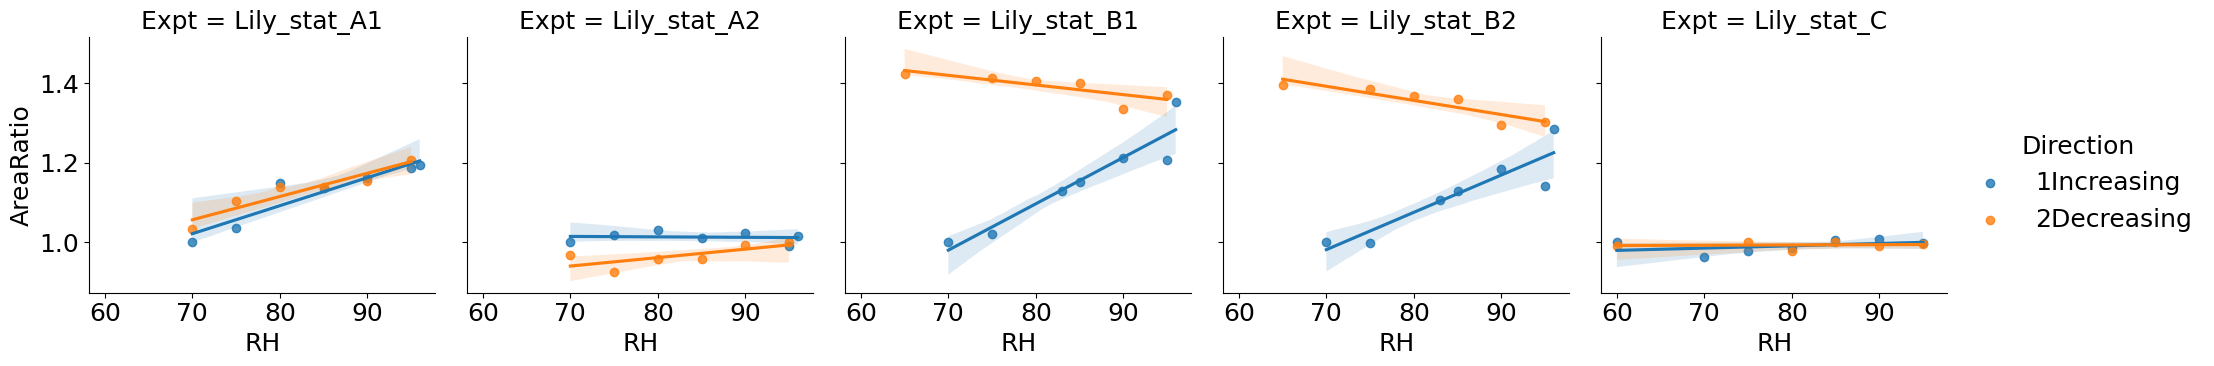

In [ ]:


plt.rcParams.update({'font.size': 18})
sns.lmplot(data=Ls, x='RH', y='AreaRatio', hue='Direction', col='Expt', height=4)
plt.show()

## 4. Linear regression per experiment (paper Section 3.4)

### Fit AreaRatio and DiameterRatio against RH

The authors fit an ordinary least-squares `LinearRegression` per experiment on the
**increasing-RH** rows, with a two-column target `[AreaRatio, DiameterRatio]`.
The loop below performs exactly the authors' selections: `Ls_inc`/`Ll_inc`/`Pl_inc` subsets for
Lilium and levitated *Populus*, and the whole `EC_stat` group for the stationary *Populus*
experiments (following the authors' own filters). Each fit maps RH (%) → the two ratios.

**実験ごとの線形回帰:** 著者と同一のデータ選択で、RH → [AreaRatio, DiameterRatio] の線形回帰を実験ごとに当てはめます。

In [ ]:


from sklearn.linear_model import LinearRegression

# (model_name, experiment label, filtered rows) — same selections as the authors' notebook
fit_specs = [
    ('LsA1', 'Lily_stat_A1', Ls_inc), ('LsA2', 'Lily_stat_A2', Ls_inc),
    ('LsB1', 'Lily_stat_B1', Ls_inc), ('LsB2', 'Lily_stat_B2', Ls_inc),
    ('LsC',  'Lily_stat_C',  Ls_inc),
    ('PsA',  'EC_stat_A',    Ps),     # authors fit EC_stat on the whole group
    ('PsB',  'EC_stat_B',    Ps),
    ('PsC',  'EC_stat_C',    Ps),
    ('LlA',  'Lily_lev_A',   Ll_inc), ('LlB', 'Lily_lev_B', Ll_inc), ('LlC', 'Lily_lev_C', Ll_inc),
    ('LlD',  'Lily_lev_D',   Ll_inc), ('LlE', 'Lily_lev_E', Ll_inc), ('LlF', 'Lily_lev_F', Ll_inc),
    ('Pl',   'EC_lev',       Pl_inc),
]

fits = {}
for name, expt, rows in fit_specs:
    sub = rows[rows['Expt'] == expt]
    x = sub['RH'].values.reshape((-1, 1))
    y = sub[['AreaRatio', 'DiameterRatio']].values
    fits[name] = LinearRegression().fit(x, y)

print(f'Fitted {len(fits)} per-experiment linear models')

Fitted 15 per-experiment linear models


### Plot the fitted models over the data

Following the authors' figure: fitted regression lines (`pred`) with the measured
AreaRatio points per experiment, one panel per group (stationary Lilium, stationary
*Populus*, levitated Lilium).

**フィット結果のプロット:** 各群の回帰直線と測定点を重ねて描画します（著者ノートブックの `linearplots.png` に対応）。

/tmp/ipykernel_946/2658562821.py:22: UserWarning: 
The markers list has fewer values (6) than needed (7) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(ax=ax[2], data=model[model['ID'] == 'Ll'], x='RH', y='AreaRatio', hue='Expt', style='Expt', markers=['o', '^', 'v', 'X', 'P', 's'], s=100)


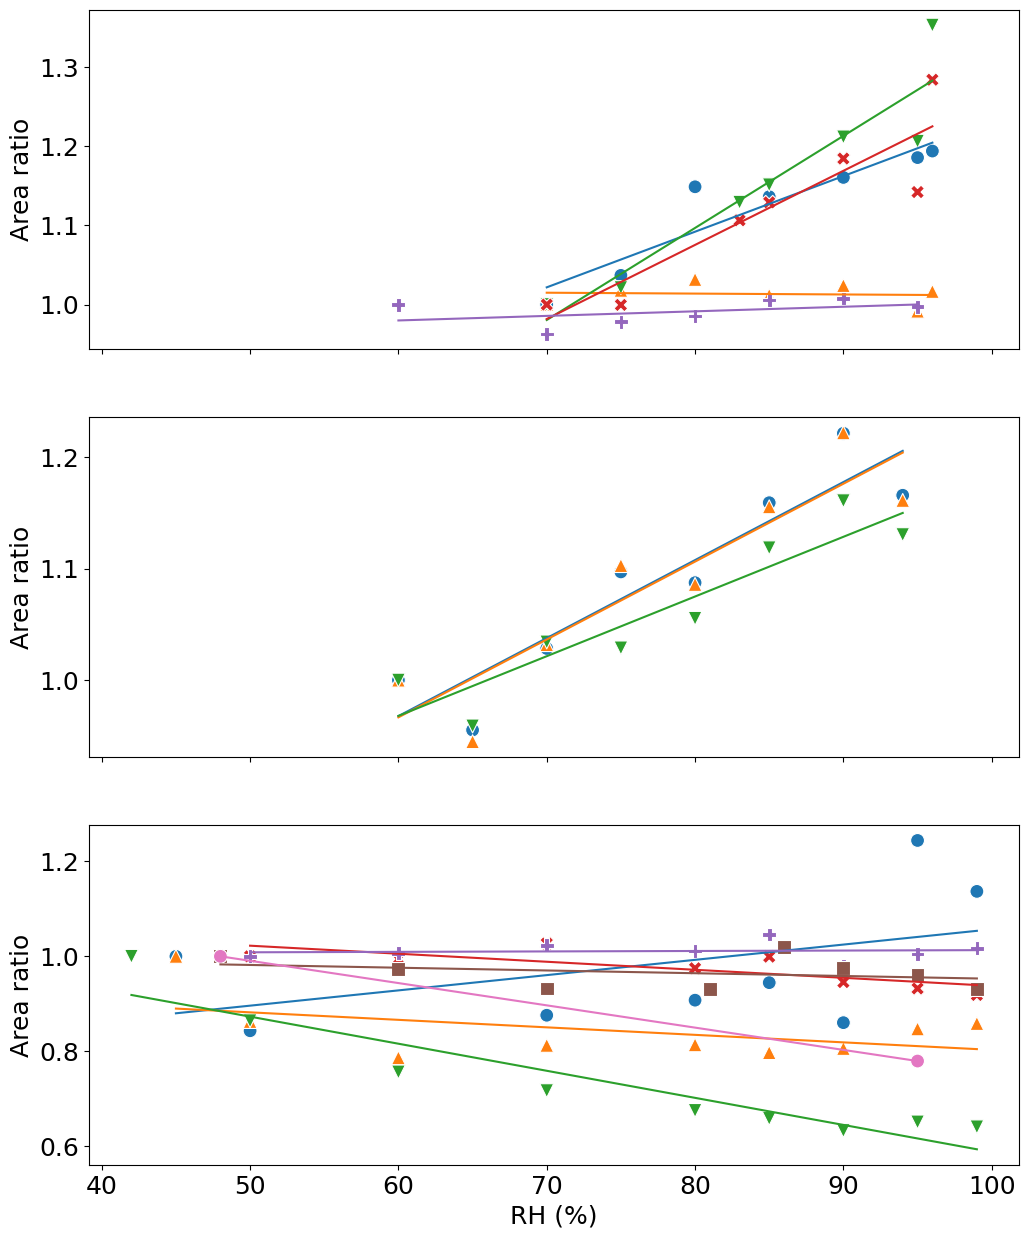

In [ ]:


model_frames = []
for name, expt, rows in fit_specs:
    sub = rows[rows['Expt'] == expt]
    x = sub['RH'].values.reshape((-1, 1))
    gid = name[:2] if name.startswith(('Ls', 'Ps')) else 'Ll'
    model_frames.append(pd.DataFrame({
        'ID': gid, 'Expt': name,
        'RH': sub['RH'].values,
        'AreaRatio': sub['AreaRatio'].values,
        'pred': fits[name].predict(x)[:, 0],
    }))
model = pd.concat(model_frames, ignore_index=True)

fig, ax = plt.subplots(3, 1, figsize=(12, 15), sharex=True)
sns.lineplot(ax=ax[0], data=model[model['ID'] == 'Ls'], x='RH', y='pred', hue='Expt').set(ylabel='Area ratio', xlabel='RH (%)')
sns.scatterplot(ax=ax[0], data=model[model['ID'] == 'Ls'], x='RH', y='AreaRatio', hue='Expt', style='Expt', markers=['o', '^', 'v', 'X', 'P'], s=100)
ax[0].legend().remove()
sns.lineplot(ax=ax[1], data=model[model['ID'] == 'Ps'], x='RH', y='pred', hue='Expt').set(ylabel='Area ratio', xlabel='RH (%)')
sns.scatterplot(ax=ax[1], data=model[model['ID'] == 'Ps'], x='RH', y='AreaRatio', hue='Expt', style='Expt', markers=['o', '^', 'v'], s=100)
ax[1].legend().remove()
sns.lineplot(ax=ax[2], data=model[model['ID'] == 'Ll'], x='RH', y='pred', hue='Expt').set(ylabel='Area ratio', xlabel='RH (%)')
sns.scatterplot(ax=ax[2], data=model[model['ID'] == 'Ll'], x='RH', y='AreaRatio', hue='Expt', style='Expt', markers=['o', '^', 'v', 'X', 'P', 's'], s=100)
ax[2].legend().remove()
plt.show()

## 5. Predictions at 60 % and 90 % RH and group comparison (paper Fig. 6)

### Predict endpoints and compute the changes

Each per-experiment model predicts AreaRatio and DiameterRatio at 60 % and 90 % RH —
the consistent interval used in Section 3.4 of the paper (the paper text mentions a
70–95 % interval in Section 2.4; the authors' analysis pins 60–90 %, which we follow).
The change columns are the differences between the two endpoints.

**60/90 % RH での予測:** 各実験モデルから 60 % と 90 % RH における面積比・径比を予測し、その変化量を計算します。

In [ ]:


records = []
group_of = {'Ls': 'Lil. stat.', 'Ps': 'Pop. stat.', 'Ll': 'Lil. lev.', 'Pl': 'Pop. lev.'}
for name, expt, _ in fit_specs:
    gid = name[:2] if name.startswith(('Ls', 'Ps')) else 'Ll'
    m = fits[name]
    records.append({
        'ID': name, 'Expt': group_of[gid],
        'Area_60%RH': m.predict([[60]])[0][0], 'Area_90%RH': m.predict([[90]])[0][0],
        'Ratio_60%RH': m.predict([[60]])[0][1], 'Ratio_90%RH': m.predict([[90]])[0][1],
    })
df = pd.DataFrame(records)

df['Area_change'] = df['Area_90%RH'] - df['Area_60%RH']
df['Ratio_change'] = df['Ratio_90%RH'] - df['Ratio_60%RH']
df

,ID,Expt,Area_60%RH,Area_90%RH,Ratio_60%RH,Ratio_90%RH,Area_change,Ratio_change
0,LsA1,Lil. stat.,0.951447,1.162418,0.787251,0.767236,0.210971,-0.020015
1,LsA2,Lil. stat.,1.016096,1.012768,0.446532,0.512310,-0.003328,0.065778
2,LsB1,Lil. stat.,0.864142,1.213210,0.573857,0.628878,0.349068,0.055021
3,LsB2,Lil. stat.,0.888089,1.169066,0.530027,0.595427,0.280977,0.065400
4,LsC,Lil. stat.,0.979923,0.997226,0.374997,0.376626,0.017304,0.001629
5,PsA,Pop. stat.,0.967741,1.177512,0.872962,0.895581,0.209771,0.022618
6,PsB,Pop. stat.,0.966646,1.176005,0.921197,0.942365,0.209359,0.021168
7,PsC,Pop. stat.,0.967933,1.128447,0.934789,0.933498,0.160514,-0.001291
8,LlA,Lil. lev.,0.928221,1.024794,0.835932,0.811732,0.096573,-0.024200
9,LlB,Lil. lev.,0.866138,0.818667,0.647120,0.655417,-0.047471,0.008298


### Box-and-whisker comparison of the four groups

This reproduces the paper's Fig. 6 summary: the distribution of fitted area-ratio change
and diameter-ratio change between 60 % and 90 % RH for each experiment group
(stationary/levitated × Lilium/*Populus*), with individual experiments overlaid as red points.

**群間比較:** 60–90 % RH における面積比・径比の変化量を群ごとに箱ひげ図で比較します（論文 Fig. 6 に対応）。

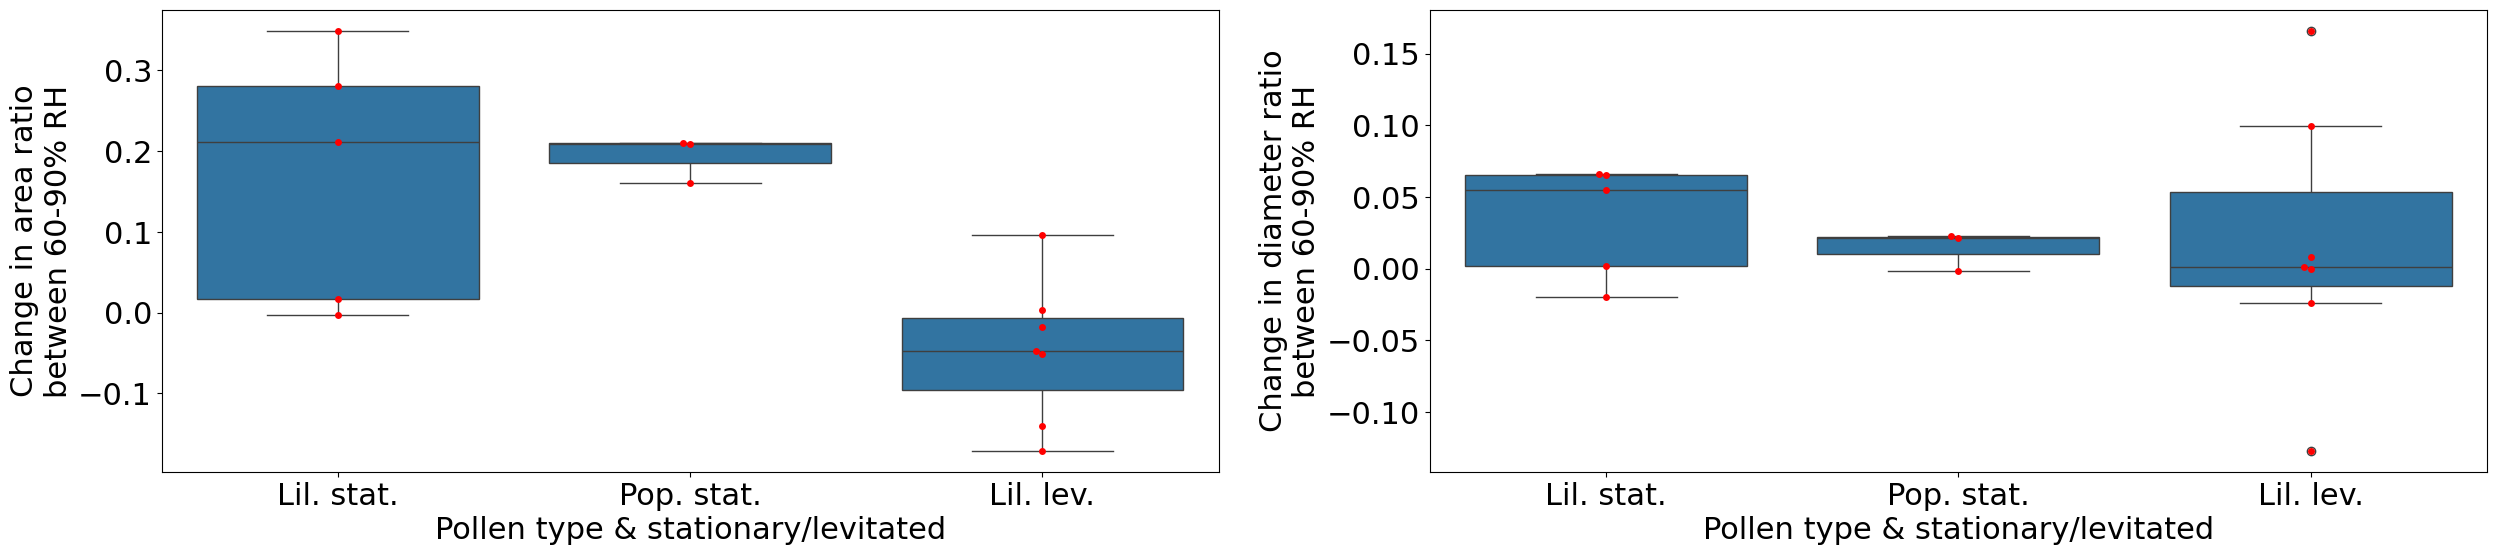

In [ ]:


plt.rcParams.update({'font.size': 22})
fig, ax = plt.subplots(1, 2, figsize=(30, 6))
sns.boxplot(ax=ax[0], data=df, x='Expt', y='Area_change').set(ylabel='Change in area ratio\nbetween 60-90% RH', xlabel='Pollen type & stationary/levitated')
sns.swarmplot(ax=ax[0], data=df, x='Expt', y='Area_change', color='red')
sns.boxplot(ax=ax[1], data=df, x='Expt', y='Ratio_change').set(ylabel='Change in diameter ratio\nbetween 60-90% RH', xlabel='Pollen type & stationary/levitated')
sns.swarmplot(ax=ax[1], data=df, x='Expt', y='Ratio_change', color='red')
plt.savefig('summaryplots.png', bbox_inches='tight')
plt.show()

### Group means

The per-group means correspond to the numbers quoted in Section 3.4 of the paper:
area increases of about 17–19 % for the surface-fixed (stationary) groups, while the
levitated groups show no consistent increase.

**群ごとの平均値:** 論文 Section 3.4 で報告されている値（表面固定群で面積 +17〜19 % 程度）に対応します。

In [ ]:


df.groupby('Expt').mean(numeric_only=True)

,Area_60%RH,Area_90%RH,Ratio_60%RH,Ratio_90%RH,Area_change,Ratio_change
Expt,,,,,,
Lil. lev.,0.934972,0.888056,0.709949,0.727656,-0.046916,0.017707
Lil. stat.,0.939939,1.110938,0.542533,0.576095,0.170998,0.033562
Pop. stat.,0.967440,1.160655,0.909649,0.923814,0.193215,0.014165


### Paired t-tests (paper Section 3.4)

The authors test, per group, whether the fitted 90 % RH endpoint differs from the 60 % RH
endpoint using a paired two-sided t-test (`scipy.stats.ttest_rel`, pairing each experiment with itself).
They test three groups only; *Pop. lev.* is a single experiment and is not tested.

**対応のある t 検定:** 各群の 90 % RH と 60 % RH の予測値を対応のある両側 t 検定で比較します（Pop. lev. は実験数 1 のため対象外）。

In [ ]:


print(scipy.stats.ttest_rel(df[df['Expt'] == 'Lil. stat.']['Area_90%RH'], df[df['Expt'] == 'Lil. stat.']['Area_60%RH']))
print(scipy.stats.ttest_rel(df[df['Expt'] == 'Lil. stat.']['Ratio_90%RH'], df[df['Expt'] == 'Lil. stat.']['Ratio_60%RH']))
print(scipy.stats.ttest_rel(df[df['Expt'] == 'Pop. stat.']['Area_90%RH'], df[df['Expt'] == 'Pop. stat.']['Area_60%RH']))
print(scipy.stats.ttest_rel(df[df['Expt'] == 'Pop. stat.']['Ratio_90%RH'], df[df['Expt'] == 'Pop. stat.']['Ratio_60%RH']))
print(scipy.stats.ttest_rel(df[df['Expt'] == 'Lil. lev.']['Area_90%RH'], df[df['Expt'] == 'Lil. lev.']['Area_60%RH']))
print(scipy.stats.ttest_rel(df[df['Expt'] == 'Lil. lev.']['Ratio_90%RH'], df[df['Expt'] == 'Lil. lev.']['Ratio_60%RH']))

TtestResult(statistic=np.float64(2.42540402677733), pvalue=np.float64(0.07233922083827914), df=np.int64(4))
TtestResult(statistic=np.float64(1.8758591528576793), pvalue=np.float64(0.13392066024411162), df=np.int64(4))
TtestResult(statistic=np.float64(11.816877197203068), pvalue=np.float64(0.007085323854370891), df=np.int64(2))
TtestResult(statistic=np.float64(1.8302964823183352), pvalue=np.float64(0.20869273283623288), df=np.int64(2))
TtestResult(statistic=np.float64(-1.3847758934484196), pvalue=np.float64(0.21541521765246419), df=np.int64(6))
TtestResult(statistic=np.float64(0.5032968512838498), pvalue=np.float64(0.6326943900143231), df=np.int64(6))


## 6. Implied mass increase (paper Section 3.5, Eq. 3)

### Convert area changes to an implied mass change

The paper converts area-ratio changes to a mass change assuming constant density and
near-sphericity: m/m₀ = (A/A₀)^(3/2) (Eq. 3). This cell is an **additional check derived from the paper text**
(it is not present in the authors' notebook): applying the exponent to each experiment's
fitted area change and averaging per group. The paper reports implied mass increases of
about 27 % (Lilium) and 30 % (*Populus*) between 60 % and 90 % RH.

**質量増加への換算:** 論文 Eq. 3（m/m₀ = (A/A₀)^(3/2)）を各実験の面積変化に適用し、群平均を論文値（約 27 % / 30 %）と比較します。

In [ ]:


df['Mass_change'] = (1.0 + df['Area_change']) ** 1.5 - 1.0
mass_means = df.groupby('Expt')['Mass_change'].mean()
print('Implied mass increase between 60-90% RH (mean per group):')
print((mass_means * 100).round(1).astype(str) + ' %')
print()
print('Paper Section 3.5 reference: ~27 % (Lilium orientalis), ~30 % (Populus deltoides)')

Implied mass increase between 60-90% RH (mean per group):
Expt
Lil. lev.     -6.7 %
Lil. stat.    27.4 %
Pop. stat.    30.4 %
Name: Mass_change, dtype: object

Paper Section 3.5 reference: ~27 % (Lilium orientalis), ~30 % (Populus deltoides)


## 7. Interpretation and limitations

**What this run shows (actual outputs above):** the fitted regressions, the 60–90 % RH endpoint
predictions, the four-group box summary (paper Fig. 6) and the paired t-tests are reproduced
from the authors' own processed data. Surface-fixed groups show a clear area increase; levitated
groups do not show a consistent increase, matching the paper's conclusion that grain orientation
changes during levitation dominate the levitated measurements.

**Limitations / 制限事項:**
- This reproduces the **summarised statistics only**. The image-level pipeline (binary threshold,
  Canny edges, contours, ellipse fits on the macroscope snapshots) lives in `DataAggregation.ipynb`
  and requires the 1 GB `ImageData.zip` — it is not executed here. Measurements are in pixel units.
- The paper text is inconsistent about the summarised RH interval (70–95 % in Section 2.4 vs
  60–90 % in Section 3.4); the authors' analysis notebook uses 60–90 %, which we follow.
- Versions differ from the authors' 2023 environment (numpy 1.24.1, pandas 1.5.3, matplotlib 3.6.3,
  seaborn 0.12.2, sklearn 1.2.1); the refactored per-experiment loop applies the authors' exact
  data selections and the same OLS fits and paired t-tests.
- A one-run re-execution does not re-validate the paper's dataset-level claims beyond the published data.

**Provenance:** paper DOI 10.5194/amt-16-4885-2023 (CC BY 4.0); data and author notebook from
UBIRA eData record 923 (https://edata.bham.ac.uk/923/), CC BY 4.0. Data file downloaded and
validated inside this notebook; no credentials required.

**参考文献:** Mills, S. A. et al., Atmos. Meas. Tech. 16, 4885–4898 (2023); UBIRA eData record 923.